## Load & Prepare Dataset

In [1]:
# ================== SEL PERSIAPAN A - Muat library & file dataset ==================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.options.display.float_format = "{:,.2f}".format

NAMA_FILE = "Data Clean.xlsx"

# Di Google Colab: kalau file belum ada, kotak upload akan muncul.
if not os.path.exists(NAMA_FILE):
    try:
        from google.colab import files
        print("Silakan pilih file:", NAMA_FILE)
        diupload = files.upload()
        NAMA_FILE = list(diupload.keys())[0]
    except ImportError:
        raise FileNotFoundError(
            f"'{NAMA_FILE}' tidak ditemukan. Letakkan file di folder yang sama dengan notebook ini."
        )

print("File siap dipakai:", NAMA_FILE)

# Palet warna kelas (mengikuti tema materi)
WARNA = {
    "tosca":  "#4BD4B1",
    "gelap":  "#0B3B36",
    "sedang": "#12615A",
    "muda":   "#BFE6DC",
    "oranye": "#E8833A",
    "merah":  "#C4553B",
    "abu":    "#7A8C89",
}
URUTAN_SEGMEN = [
    "Champions", "Loyal Customers", "Potential Loyalist", "Need Attention",
    "At Risk", "Can't Lose Them", "Hibernating",
]
WARNA_SEGMEN = {
    "Champions":          "#0B3B36",
    "Loyal Customers":    "#12615A",
    "Potential Loyalist": "#4BD4B1",
    "Need Attention":     "#BFE6DC",
    "At Risk":            "#E8833A",
    "Can't Lose Them":    "#C4553B",
    "Hibernating":        "#7A8C89",
}

def rp(x):
    """Format angka menjadi Rupiah singkat, mis. 3_008_035_000 -> 'Rp 3,01 M'."""
    x = float(x)
    if abs(x) >= 1_000_000_000:
        return f"Rp {x/1_000_000_000:,.2f} M".replace(",", "#").replace(".", ",").replace("#", ".")
    if abs(x) >= 1_000_000:
        return f"Rp {x/1_000_000:,.1f} jt".replace(",", "#").replace(".", ",").replace("#", ".")
    return f"Rp {x:,.0f}".replace(",", ".")

print("Sel Persiapan A selesai.")

File siap dipakai: Data Clean.xlsx
Sel Persiapan A selesai.


In [2]:
# ================== SEL PERSIAPAN B - Baca & rapikan data (sudah disiapkan) ==================

orders = pd.read_excel(NAMA_FILE, sheet_name="Order_Master")
customers  = pd.read_excel(NAMA_FILE, sheet_name="Customer_Master")
products   = pd.read_excel(NAMA_FILE, sheet_name="Product_Master")

print(f"Baris order siap pakai: {len(orders):,}")
print(f"Rentang tanggal       : {orders['order_date'].min():%d %b %Y} s/d {orders['order_date'].max():%d %b %Y}")
print("Sel Persiapan B selesai.")

Baris order siap pakai: 25,790
Rentang tanggal       : 01 Jan 2024 s/d 31 Dec 2025
Sel Persiapan B selesai.


## EDA

### Ukuran Data

In [3]:
print("orders   :", orders.shape)
print("customers:", customers.shape)
print("products :", products.shape)

display(orders.head())

print("\nPelanggan unik di orders   :", orders["customer_id"].nunique())
print("Pelanggan terdaftar         :", customers["customer_id"].nunique())
print("Belum pernah belanja        :",
      customers["customer_id"].nunique() - orders["customer_id"].nunique())

orders   : (25790, 30)
customers: (15000, 21)
products : (50, 8)


,order_id,order_date,tahun,bulan,customer_id,product_id,product_name,category,quantity,unit_price,discount_pct,channel,payment_method,city,province,order_status,rating,review_text,revenue,unit_cost,profit,is_diskon,diskon value,order_date_bantu,multiply angka,channel bantu,city bantu,province bantu,quantity bantu,quantity bantu 2
0,ORD-2024-000001,2024-01-01,2024,2024-01,CUST-00197,PRD-005,Arabika Flores Bajawa 200g,Roasted Beans,4,113000,0.00,Shopee,GoPay,Balikpapan,Kalimantan Timur,Completed,2.00,"Paket sempat nyasar, respon admin lama.",452000,52500,242000,No,0,2024-01-01,1.00,Shopee,Balikpapan,Kalimantan Timur,4,4
1,ORD-2024-000002,2024-01-01,2024,2024-01,CUST-00515,PRD-010,Espresso Blend 250g,Roasted Beans,3,99000,0.10,TikTok Shop,Paylater,Palembang,Sumatera Selatan,Completed,2.00,"Kemasan bocor, isinya tumpah di dus.",267300,39500,148800,Yes,29700,2024-01-01,NaN,TikTok Shop,Palembang,Sumatera Selatan,3,3
2,ORD-2024-000003,2024-01-01,2024,2024-01,CUST-00790,PRD-038,Insulated Tumbler 400ml,Accessories,3,135000,0.00,Webstore,OVO,Balikpapan,Kalimantan Timur,Completed,5.00,NaN,405000,75500,178500,No,0,2024-01-01,NaN,Webstore,Balikpapan,Kalimantan Timur,3,3
3,ORD-2024-000004,2024-01-01,2024,2024-01,CUST-01167,PRD-014,Cold Brew Blend 500g,Roasted Beans,2,178000,0.00,TikTok Shop,GoPay,Tangerang,Banten,Completed,3.00,"Sesuai deskripsi, harga agak mahal.",356000,71000,214000,No,0,2024-01-01,NaN,TikTok Shop,Tangerang,Banten,2,2
4,ORD-2024-000005,2024-01-01,2024,2024-01,CUST-01194,PRD-013,Manuk Gading Natural 200g,Roasted Beans,5,145000,0.00,Webstore,DANA,Semarang,Jawa Tengah,Completed,5.00,"Gift set-nya cantik, penerima suka banget.",725000,66500,392500,No,0,2024-01-01,NaN,Webstore,Semarang,Jawa Tengah,5,5



Pelanggan unik di orders   : 13380
Pelanggan terdaftar         : 15000
Belum pernah belanja        : 1620


### Kualitas Akuisisi Channel

In [4]:
total_revenue = orders["revenue"].sum()
jumlah_order  = orders["order_id"].nunique()
jumlah_pelanggan = orders["customer_id"].nunique()
aov = total_revenue/jumlah_order

print("Total revenue    :", rp(total_revenue))
print("Jumlah order     :", f"{jumlah_order:,}")
print("Jumlah pelanggan :", f"{jumlah_pelanggan:,}")
print("AOV              :", rp(aov))

per_channel = (
    orders.groupby("channel")
          .agg(revenue=("revenue", "sum"),
               order=("order_id", "nunique"))
)
per_channel["kontribusi_%"] = per_channel["revenue"] / total_revenue * 100
per_channel["aov"] = per_channel["revenue"] / per_channel["order"]
display(per_channel.sort_values("revenue", ascending=False).round(1))

Total revenue    : Rp 7,29 M
Jumlah order     : 25,790
Jumlah pelanggan : 13,380
AOV              : Rp 282.572


,revenue,order,kontribusi_%,aov
channel,,,,
Tokopedia,2101556100,7498,28.80,"280,282.20"
Shopee,2018834450,7149,27.70,"282,394.00"
Webstore,1593138250,5609,21.90,"284,032.50"
TikTok Shop,1574008000,5534,21.60,"284,425.00"


### Recency Customer berdasarkan Snapshot Tanggal

In [5]:
snapshot_date = orders["order_date"].max() + pd.Timedelta(days=1)
print("Transaksi terakhir :", orders["order_date"].max().strftime("%d %b %Y"))
print("Snapshot date      :", snapshot_date.strftime("%d %b %Y"))

terakhir = orders.groupby("customer_id")["order_date"].max()

recency = (snapshot_date - terakhir).dt.days
recency.name = "Recency"

display(recency.head())
print("\nRecency  min:", recency.min(), "hari | median:", int(recency.median()),
      "hari | max:", recency.max(), "hari")

Transaksi terakhir : 31 Dec 2025
Snapshot date      : 01 Jan 2026


customer_id
CUST-00001    289
CUST-00002     85
CUST-00003    341
CUST-00004    301
CUST-00005    588
Name: Recency, dtype: int64


Recency  min: 1 hari | median: 197 hari | max: 731 hari


### Membuat metrik RFM

In [6]:
rfm = (
    orders.groupby("customer_id")
          .agg(
            Recency   = ("order_date", lambda s: (snapshot_date - s.max()).days),
              Frequency = ("order_id", "nunique"),
              Monetary  = ("revenue", "sum"),
          )
          .reset_index()
)

print("Jumlah baris rfm:", len(rfm), "(harus sama dengan jumlah pelanggan unik)")
display(rfm.head())
display(rfm[["Recency", "Frequency", "Monetary"]].describe().round(1))

Jumlah baris rfm: 13380 (harus sama dengan jumlah pelanggan unik)


,customer_id,Recency,Frequency,Monetary
0,CUST-00001,289,3,721000
1,CUST-00002,85,10,3049750
2,CUST-00003,341,1,114000
3,CUST-00004,301,2,255000
4,CUST-00005,588,3,613500


,Recency,Frequency,Monetary
count,"13,380.00","13,380.00","13,380.00"
mean,245.80,1.90,"544,659.00"
std,192.90,1.50,"578,328.20"
min,1.00,1.00,0.00
25%,83.00,1.00,"171,000.00"
50%,197.00,1.00,"343,800.00"
75%,380.00,2.00,"697,250.00"
max,731.00,11.00,"7,143,500.00"


#### Mapping Skor Recency

In [7]:
rfm["R_Score"] = pd.qcut(rfm["Recency"], q=5, labels=[5, 4, 3, 2, 1]).astype(int)

batas_r = rfm.groupby("R_Score")["Recency"].agg(["min", "max", "count"])
batas_r.index.name = "R_Score"
display(batas_r)

print("\nTerjemahan bisnisnya:")
for skor in [5, 4, 3, 2, 1]:
    b = batas_r.loc[skor]
    print(f"  R_Score {skor}: belanja terakhir {int(b['min'])}-{int(b['max'])} hari lalu "
          f"({int(b['count'])} pelanggan)")

,min,max,count
R_Score,,,
1,428,731,2668
2,261,427,2683
3,146,260,2656
4,65,145,2661
5,1,64,2712



Terjemahan bisnisnya:
  R_Score 5: belanja terakhir 1-64 hari lalu (2712 pelanggan)
  R_Score 4: belanja terakhir 65-145 hari lalu (2661 pelanggan)
  R_Score 3: belanja terakhir 146-260 hari lalu (2656 pelanggan)
  R_Score 2: belanja terakhir 261-427 hari lalu (2683 pelanggan)
  R_Score 1: belanja terakhir 428-731 hari lalu (2668 pelanggan)


#### Mapping Skor Frequency & Monetary

In [8]:
def skor_frequency(jumlah_order):
    """Ambang bisnis: >=6 -> 5, 4-5 -> 4, 3 -> 3, 2 -> 2, 1 -> 1."""
    if jumlah_order >= 6:
        return 5
    elif jumlah_order >= 4:
        return 4
    elif jumlah_order == 3:
        return 3
    elif jumlah_order == 2:
        return 2
    return 1

rfm["F_Score"] = rfm["Frequency"].apply(skor_frequency)

rfm["M_Score"] = pd.qcut(rfm["Monetary"], q=5, labels=[1,2,3,4,5]).astype(int)

rfm["RFM_Score"] = rfm["R_Score"] + rfm["F_Score"] + rfm["M_Score"]
rfm["RFM_Cell"]  = rfm["R_Score"].astype(str) + rfm["F_Score"].astype(str) + rfm["M_Score"].astype(str)

display(rfm.head())

display(rfm.sort_values("RFM_Score", ascending=False).head(5))

print("\nSebaran F_Score:")
print(rfm.groupby("F_Score")["Frequency"].agg(["min", "max", "count"]))

,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Cell
0,CUST-00001,289,3,721000,2,3,4,9,234
1,CUST-00002,85,10,3049750,4,5,5,14,455
2,CUST-00003,341,1,114000,2,1,1,4,211
3,CUST-00004,301,2,255000,2,2,2,6,222
4,CUST-00005,588,3,613500,1,3,4,8,134


,customer_id,Recency,Frequency,Monetary,R_Score,F_Score,M_Score,RFM_Score,RFM_Cell
4961,CUST-04974,52,7,2590000,5,5,5,15,555
6656,CUST-06677,20,7,2731500,5,5,5,15,555
607,CUST-00610,10,7,1401500,5,5,5,15,555
1383,CUST-01387,56,7,1426800,5,5,5,15,555
2359,CUST-02366,16,6,2155250,5,5,5,15,555



Sebaran F_Score:
         min  max  count
F_Score                 
1          1    1   7746
2          2    2   2644
3          3    3   1268
4          4    5   1162
5          6   11    560


## Segmentasi Pelanggan

### Segmentasi Awal

In [9]:
def segmentasi_demo(baris):
    """Versi awal - baru 3 aturan. Kita lengkapi di latihan berikutnya."""
    r, f, m = baris["R_Score"], baris["F_Score"], baris["M_Score"]

    if r >= 4 and f >= 4 and m >= 4:        # paling spesifik -> paling atas
        return "Champions"
    if r >= 3 and f >= 3:
        return "Loyal Customers"
    if r <= 2 and f <= 2:
        return "Hibernating"
    return "Belum terklasifikasi"

rfm["Segment_Demo"] = rfm.apply(segmentasi_demo, axis=1)
display(rfm["Segment_Demo"].value_counts().to_frame("jumlah_pelanggan"))

sisa = (rfm["Segment_Demo"] == "Belum terklasifikasi").sum()
print(f"\nMasih ada {sisa:,} pelanggan ({sisa/len(rfm):.1%}) yang belum punya nama segmen.")

,jumlah_pelanggan
Segment_Demo,
Belum terklasifikasi,6725
Hibernating,4508
Loyal Customers,1234
Champions,913



Masih ada 6,725 pelanggan (50.3%) yang belum punya nama segmen.


### Segmentasi Lanjutan

In [10]:
def segmentasi(baris):
    """Terjemahkan R/F/M Score menjadi nama segmen. Urutan aturan menentukan hasil!"""
    r, f, m = baris["R_Score"], baris["F_Score"], baris["M_Score"]

    if r>= 4 and f>=4 and m>=4:
        return "Champions"
    elif r>=3 and f>=3:
        return "Loyal Customers"
    elif r>=4 and f<=2:
        return "Potential Loyalist"
    elif r<=2 and f>=4:
        return "Can't Lose Them"
    elif r<=2 and f==3:
        return "At Risk"
    elif r<=2 and f<=2:
        return "Hibernating"

    return "Need Attention"   # penampung terakhir

rfm["Segment"] = rfm.apply(segmentasi, axis=1)

assert rfm["Segment"].notna().all(), "Masih ada pelanggan tanpa segmen!"
assert rfm["Segment"].nunique() == 7, "Jumlah segmen belum 7"

ringkas_segmen = (
    rfm.groupby("Segment", dropna=False)
       .agg(jumlah_pelanggan=("customer_id", "count"))
       .reindex(URUTAN_SEGMEN, fill_value=0)
       .reset_index()
       .rename(columns={"index": "Segment"})
       .assign(persentase=lambda d: d["jumlah_pelanggan"] / d["jumlah_pelanggan"].sum() * 100)
)

display(ringkas_segmen)

,Segment,jumlah_pelanggan,persentase
0,Champions,913,6.82
1,Loyal Customers,1234,9.22
2,Potential Loyalist,3935,29.41
3,Need Attention,1947,14.55
4,At Risk,470,3.51
5,Can't Lose Them,373,2.79
6,Hibernating,4508,33.69


### Visualisasi Segmen Pelanggan

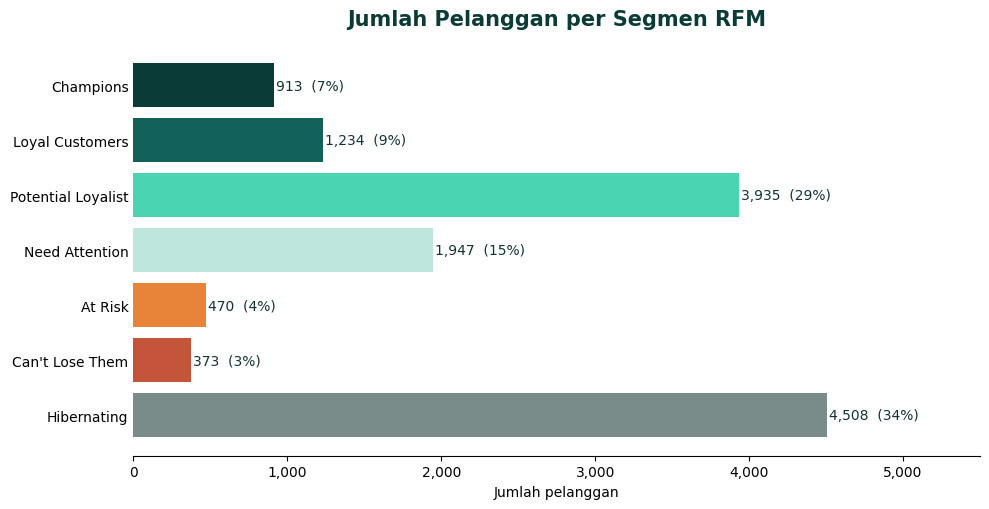

In [11]:
jumlah = rfm["Segment"].value_counts().reindex(URUTAN_SEGMEN)

fig, ax = plt.subplots(figsize=(10, 5.2))
bars = ax.barh(
    jumlah.index[::-1], jumlah.values[::-1],
    color=[WARNA_SEGMEN[s] for s in jumlah.index[::-1]],
)

# Label nilai langsung di ujung bar - lebih mudah dibaca daripada sumbu X
for bar, nilai in zip(bars, jumlah.values[::-1]):
    ax.text(bar.get_width() + 12, bar.get_y() + bar.get_height() / 2,
            f"{nilai:,}  ({nilai/len(rfm):.0%})",
            va="center", fontsize=10, color="#123331")

ax.set_title("Jumlah Pelanggan per Segmen RFM", fontsize=15, fontweight="bold",
             color="#0B3B36", pad=14)
ax.set_xlabel("Jumlah pelanggan")
ax.set_xlim(0, jumlah.max() * 1.22)
ax.xaxis.set_major_formatter(mticker.StrMethodFormatter("{x:,.0f}"))
for sisi in ["top", "right", "left"]:
    ax.spines[sisi].set_visible(False)
ax.tick_params(axis="y", length=0)
plt.tight_layout()
plt.show()

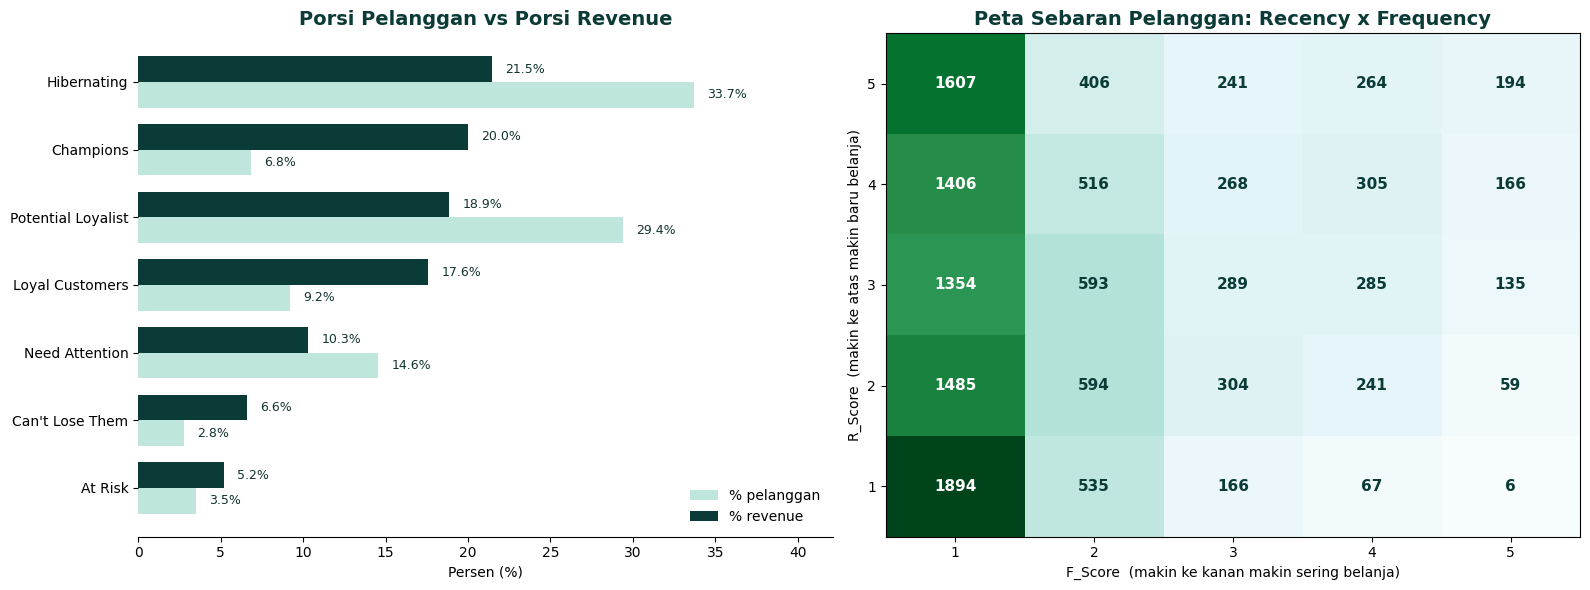

In [12]:
# --- Pareto dengan label nilai di ujung bar ---
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))

# ---------- (a) Pareto: % pelanggan vs % revenue ----------
pareto = (
    rfm.groupby("Segment")
       .agg(
           pelanggan=("customer_id", "count"),
           revenue=("Monetary", "sum")
       )
)
pareto["pct_pelanggan"] = pareto["pelanggan"] / pareto["pelanggan"].sum() * 100
pareto["pct_revenue"] = pareto["revenue"] / pareto["revenue"].sum() * 100
pareto = pareto.sort_values("pct_revenue")

y = np.arange(len(pareto))
tinggi = 0.38

bars_pelanggan = ax1.barh(
    y - tinggi / 2,
    pareto["pct_pelanggan"],
    height=tinggi,
    label="% pelanggan",
    color=WARNA["muda"]
)
bars_revenue = ax1.barh(
    y + tinggi / 2,
    pareto["pct_revenue"],
    height=tinggi,
    label="% revenue",
    color=WARNA["gelap"]
)

# label di ujung tiap bar
for bar, val in zip(bars_pelanggan, pareto["pct_pelanggan"]):
    ax1.text(
        bar.get_width() + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.1f}%",
        va="center",
        ha="left",
        fontsize=9,
        color="#123331"
    )

for bar, val in zip(bars_revenue, pareto["pct_revenue"]):
    ax1.text(
        bar.get_width() + 0.8,
        bar.get_y() + bar.get_height() / 2,
        f"{val:.1f}%",
        va="center",
        ha="left",
        fontsize=9,
        color="#123331"
    )

ax1.set_yticks(y)
ax1.set_yticklabels(pareto.index)
ax1.set_title("Porsi Pelanggan vs Porsi Revenue", fontsize=14, fontweight="bold", color="#0B3B36")
ax1.set_xlabel("Persen (%)")
ax1.set_xlim(0, max(pareto["pct_pelanggan"].max(), pareto["pct_revenue"].max()) * 1.25)
ax1.legend(frameon=False, loc="lower right")

for sisi in ["top", "right", "left"]:
    ax1.spines[sisi].set_visible(False)

# ---------- (b) Heatmap R x F ----------
matriks = pd.crosstab(rfm["R_Score"], rfm["F_Score"])
matriks = matriks.sort_index(ascending=False)

gambar = ax2.imshow(matriks.values, cmap="BuGn", aspect="auto")
ax2.set_xticks(range(len(matriks.columns)))
ax2.set_xticklabels(matriks.columns)
ax2.set_yticks(range(len(matriks.index)))
ax2.set_yticklabels(matriks.index)
ax2.set_xlabel("F_Score  (makin ke kanan makin sering belanja)")
ax2.set_ylabel("R_Score  (makin ke atas makin baru belanja)")
ax2.set_title("Peta Sebaran Pelanggan: Recency x Frequency", fontsize=14, fontweight="bold", color="#0B3B36")

for i in range(matriks.shape[0]):
    for j in range(matriks.shape[1]):
        nilai = matriks.iloc[i, j]
        ax2.text(
            j, i, f"{nilai}",
            ha="center", va="center",
            color="white" if nilai > matriks.values.max() * 0.55 else "#0B3B36",
            fontsize=11, fontweight="bold"
        )

plt.tight_layout()
plt.show()

### Tabel Value tiap Segmen Pelanggan

In [13]:
profil = (
    rfm.groupby("Segment")
       .agg(
           jumlah_pelanggan = ("customer_id", "count"),
           avg_recency      = ("Recency", "mean"),
           avg_frequency    = ("Frequency", "mean"),
           avg_monetary     = ("Monetary", "mean"),
           total_revenue    = ("Monetary", "sum"),
       )
       .sort_values("total_revenue", ascending=False)
)

profil["pct_pelanggan"]   = profil["jumlah_pelanggan"] / profil["jumlah_pelanggan"].sum() * 100
profil["pct_revenue"]     = profil["total_revenue"]    / profil["total_revenue"].sum()    * 100
profil["revenue_per_org"] = profil["total_revenue"]    / profil["jumlah_pelanggan"]

tampil = profil.copy()
tampil["avg_recency"]     = tampil["avg_recency"].round(0).astype(int).astype(str) + " hari"
tampil["avg_frequency"]   = tampil["avg_frequency"].round(1)
tampil["avg_monetary"]    = tampil["avg_monetary"].apply(rp)
tampil["total_revenue"]   = tampil["total_revenue"].apply(rp)
tampil["revenue_per_org"] = tampil["revenue_per_org"].apply(rp)
tampil["pct_pelanggan"]   = tampil["pct_pelanggan"].round(1)
tampil["pct_revenue"]     = tampil["pct_revenue"].round(1)

display(tampil)

,jumlah_pelanggan,avg_recency,avg_frequency,avg_monetary,total_revenue,pct_pelanggan,pct_revenue,revenue_per_org
Segment,,,,,,,,
Hibernating,4508,460 hari,1.30,Rp 346.807,"Rp 1,56 M",33.70,21.50,Rp 346.807
Champions,913,68 hari,5.50,"Rp 1,6 jt","Rp 1,46 M",6.80,20.00,"Rp 1,6 jt"
Potential Loyalist,3935,67 hari,1.20,Rp 349.354,"Rp 1,37 M",29.40,18.90,Rp 349.354
Loyal Customers,1234,144 hari,3.70,"Rp 1,0 jt","Rp 1,28 M",9.20,17.60,"Rp 1,0 jt"
Need Attention,1947,199 hari,1.30,Rp 385.233,"Rp 750,0 jt",14.60,10.30,Rp 385.233
Can't Lose Them,373,359 hari,4.70,"Rp 1,3 jt","Rp 481,8 jt",2.80,6.60,"Rp 1,3 jt"
At Risk,470,399 hari,3.00,Rp 808.548,"Rp 380,0 jt",3.50,5.20,Rp 808.548


In [14]:
display(
    tampil.reset_index()[["Segment", "jumlah_pelanggan", "pct_pelanggan", "total_revenue", "pct_revenue"]]
)

,Segment,jumlah_pelanggan,pct_pelanggan,total_revenue,pct_revenue
0,Hibernating,4508,33.70,"Rp 1,56 M",21.50
1,Champions,913,6.80,"Rp 1,46 M",20.00
2,Potential Loyalist,3935,29.40,"Rp 1,37 M",18.90
3,Loyal Customers,1234,9.20,"Rp 1,28 M",17.60
4,Need Attention,1947,14.60,"Rp 750,0 jt",10.30
5,Can't Lose Them,373,2.80,"Rp 481,8 jt",6.60
6,At Risk,470,3.50,"Rp 380,0 jt",5.20


### Tabel Revenue at Risk & Potential Revenue

In [17]:
segmen_berisiko = ["At Risk", "Can't Lose Them"]
revenue_at_risk = rfm[rfm["Segment"].isin(segmen_berisiko)]["Monetary"].sum()
pct_at_risk = revenue_at_risk / total_revenue * 100
print("Revenue at risk :", rp(revenue_at_risk), f"({pct_at_risk:.1f}% dari total)")

pl = rfm[rfm["Segment"] == "Potential Loyalist"]
nilai_per_order = pl["Monetary"].mean() / pl["Frequency"].mean()
frekuensi_target = 2
tambahan_revenue = (frekuensi_target - pl["Frequency"].mean()) * nilai_per_order * len(pl)
print("Potensi tambahan revenue Upside:", rp(tambahan_revenue))

target = (
    rfm[rfm["Segment"] == "Can't Lose Them"]
      .merge(customers[["customer_id", "customer_name", "city"]], on="customer_id", how="left")
      [["customer_id", "customer_name", "city", "Recency", "Frequency", "Monetary"]]
      .sort_values("Monetary", ascending=False)
)

display(target.head(10))

Revenue at risk : Rp 861,9 jt (11.8% dari total)
Potensi tambahan revenue Upside: Rp 852,8 jt


,customer_id,customer_name,city,Recency,Frequency,Monetary
38,CUST-00662,Oki Yulianti,Jakarta,280,7,5862050
44,CUST-00741,Hilda Yulianti,Bandung,404,5,5130000
118,CUST-02205,Hesti Suryadi,Balikpapan,277,10,4892100
84,CUST-01395,Sari Ramadhan,Balikpapan,404,11,4020150
223,CUST-04338,Eka Kusuma,Pekanbaru,407,4,3473100
175,CUST-03349,Vero Santoso,Balikpapan,292,7,3345250
49,CUST-00817,Hana Cahyani,Tangerang,298,5,3203000
203,CUST-03839,Nanda Setiawan,Bandung,367,6,3047400
351,CUST-08987,Zaki Rahayu,Balikpapan,338,7,3039600
366,CUST-09978,Jihan Utami,Balikpapan,286,7,2914100
